## MENTAL HEALTH PREDICTION

### About our data set

#### This dataset examines how the use of digital devices—such as phones, laptops, tablets, and TVs—relates to different aspects of mental health. It includes self-reported information on screen time, daily routines, mood, stress levels, physical activity, and overall mental well-being. The goal is to uncover patterns and insights into how our digital habits might influence mental health in today’s lifestyle.
### 🎯 Objective: Classify the mental health score

## the data contains 
### categorical variables : 'user_id', 'gender', 'location_type' and 
### Numerical variables : 'daily_screen_time_hours' 'phone_usage_hours'	'laptop_usage_hours' 'tablet_usage_hours'	'tv_usage_hours'	'social_media_hours'	'work_related_hours' 'stress_level'	'physical_activity_hours_per_week'	'mental_health_score'	'uses_wellness_apps'	'eats_healthy'	'caffeine_intake_mg_per_day'	'weekly_anxiety_score'	'weekly_depression_score'	'mindfulness_minutes_per_day'

### dtype: int64=10  ,float64=13, object=2
### our data has no missing values and it's almostly balanced

## Analyze the Structure of the Data

##### 📦 Importing Required Libraries

In [1]:
import pandas as pd 
import pathlib
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

In [2]:
df= pd.read_csv("c:/Users/BCSbgayet/Downloads/digital_diet_mental_health.csv")
df.head()

,user_id,age,gender,daily_screen_time_hours,phone_usage_hours,laptop_usage_hours,tablet_usage_hours,tv_usage_hours,social_media_hours,work_related_hours,...,stress_level,physical_activity_hours_per_week,location_type,mental_health_score,uses_wellness_apps,eats_healthy,caffeine_intake_mg_per_day,weekly_anxiety_score,weekly_depression_score,mindfulness_minutes_per_day
0,user_1,51,Female,4.8,3.4,1.3,1.6,1.6,4.1,2.0,...,10,0.7,Urban,32,1,1,125.2,13,15,4.0
1,user_2,64,Male,3.9,3.5,1.8,0.9,2.0,2.7,3.1,...,6,4.3,Suburban,75,0,1,150.4,19,18,6.5
2,user_3,41,Other,10.5,2.1,2.6,0.7,2.2,3.0,2.8,...,5,3.1,Suburban,22,0,0,187.9,7,3,6.9
3,user_4,27,Other,8.8,0.0,0.0,0.7,2.5,3.3,1.6,...,5,0.0,Rural,22,0,1,73.6,7,2,4.8
4,user_5,55,Male,5.9,1.7,1.1,1.5,1.6,1.1,3.6,...,7,3.0,Urban,64,1,1,217.5,8,10,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   user_id                           2000 non-null   object 
 1   age                               2000 non-null   int64  
 2   gender                            2000 non-null   object 
 3   daily_screen_time_hours           2000 non-null   float64
 4   phone_usage_hours                 2000 non-null   float64
 5   laptop_usage_hours                2000 non-null   float64
 6   tablet_usage_hours                2000 non-null   float64
 7   tv_usage_hours                    2000 non-null   float64
 8   social_media_hours                2000 non-null   float64
 9   work_related_hours                2000 non-null   float64
 10  entertainment_hours               2000 non-null   float64
 11  gaming_hours                      2000 non-null   float64
 12  sleep_

In [ ]:
df.isnull().sum()

user_id                             0
age                                 0
gender                              0
daily_screen_time_hours             0
phone_usage_hours                   0
laptop_usage_hours                  0
tablet_usage_hours                  0
tv_usage_hours                      0
social_media_hours                  0
work_related_hours                  0
entertainment_hours                 0
gaming_hours                        0
sleep_duration_hours                0
sleep_quality                       0
mood_rating                         0
stress_level                        0
physical_activity_hours_per_week    0
location_type                       0
mental_health_score                 0
uses_wellness_apps                  0
eats_healthy                        0
caffeine_intake_mg_per_day          0
weekly_anxiety_score                0
weekly_depression_score             0
mindfulness_minutes_per_day         0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,age,daily_screen_time_hours,phone_usage_hours,laptop_usage_hours,tablet_usage_hours,tv_usage_hours,social_media_hours,work_related_hours,entertainment_hours,gaming_hours,...,mood_rating,stress_level,physical_activity_hours_per_week,mental_health_score,uses_wellness_apps,eats_healthy,caffeine_intake_mg_per_day,weekly_anxiety_score,weekly_depression_score,mindfulness_minutes_per_day
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.0000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.00000,2000.000000
mean,38.805500,6.025600,3.023700,1.999950,0.995650,1.503700,2.039200,2.010250,2.46735,1.2795,...,5.591000,5.541500,3.087150,49.650500,0.387500,0.507500,148.07970,9.887500,10.04900,10.753750
std,14.929203,1.974123,1.449399,0.997949,0.492714,0.959003,1.133435,1.116111,1.23686,0.8945,...,2.899814,2.885731,1.885258,17.546717,0.487301,0.500069,48.86066,6.027853,6.05334,7.340269
min,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.0000,...,1.000000,1.000000,0.000000,20.000000,0.000000,0.000000,0.80000,0.000000,0.00000,0.000000
25%,26.000000,4.700000,2.000000,1.300000,0.600000,0.800000,1.200000,1.200000,1.60000,0.6000,...,3.000000,3.000000,1.600000,35.000000,0.000000,0.000000,113.90000,5.000000,5.00000,4.900000
50%,39.000000,6.000000,3.000000,2.000000,1.000000,1.500000,2.000000,2.000000,2.40000,1.2000,...,6.000000,6.000000,3.000000,49.000000,0.000000,1.000000,147.45000,10.000000,10.00000,10.400000
75%,51.000000,7.325000,4.000000,2.700000,1.300000,2.200000,2.800000,2.800000,3.30000,1.9000,...,8.000000,8.000000,4.400000,64.250000,1.000000,1.000000,180.70000,15.000000,15.00000,15.800000
max,64.000000,13.300000,8.400000,5.600000,2.500000,4.700000,5.800000,5.900000,6.80000,4.0000,...,10.000000,10.000000,9.700000,80.000000,1.000000,1.000000,364.90000,20.000000,20.00000,36.400000


In [ ]:
def data_diagnostic(df):
        print("#"*50)
        print(df.info())
        print("#"*50)
        print("The number of total rows  {x: .0f} ".format(x=df.shape[0]))
        print("The number of total variables {x: .0f} ".format(x=df.shape[1]))
        print("The variables names {x:} ".format(x=list(df.columns.values)))

        column_headers =list(df.columns.values)
        qualitative_columns = [col for col in column_headers if df[col].dtype=="object"]
        quantitative_columns = [col for col in column_headers if df[col].dtype in ['int64', 'float64']]

        print("The qualitative variables {x:} ".format(x=qualitative_columns))
        print("The quantitative variables {x:} ".format(x=quantitative_columns))
        print("#"*50)
        print("Total number missing value {x:} ".format(x=df.isnull().sum()))

data_diagnostic(df)

##################################################
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   user_id                           2000 non-null   object 
 1   age                               2000 non-null   int64  
 2   gender                            2000 non-null   object 
 3   daily_screen_time_hours           2000 non-null   float64
 4   phone_usage_hours                 2000 non-null   float64
 5   laptop_usage_hours                2000 non-null   float64
 6   tablet_usage_hours                2000 non-null   float64
 7   tv_usage_hours                    2000 non-null   float64
 8   social_media_hours                2000 non-null   float64
 9   work_related_hours                2000 non-null   float64
 10  entertainment_hours               2000 non-null   float64
 11  gaming_hours      

In [4]:
df=df.drop(columns='user_id')


In [5]:
median_score = df['mental_health_score'].median()
df['mental_health_binary'] = (df['mental_health_score'] >= median_score).astype(int)


In [6]:
df=df.drop(columns='mental_health_score')

# Analyse univarie

### Numerical varaiables

In [ ]:
dtypes = df.dtypes.to_frame().reset_index()
dtypes.columns = ['col', 'dtype']
print('Df dtypes:')
dtypes.groupby('dtype').size()


Df dtypes:


dtype
int64       9
float64    13
object      2
dtype: int64

In [ ]:
def numeric_analysis(df):
        
    
        return print(df.describe().T)

numeric_analysis(df)

                                   count       mean        std   min    25%  \
age                               2000.0   38.80550  14.929203  13.0   26.0   
daily_screen_time_hours           2000.0    6.02560   1.974123   0.0    4.7   
phone_usage_hours                 2000.0    3.02370   1.449399   0.0    2.0   
laptop_usage_hours                2000.0    1.99995   0.997949   0.0    1.3   
tablet_usage_hours                2000.0    0.99565   0.492714   0.0    0.6   
tv_usage_hours                    2000.0    1.50370   0.959003   0.0    0.8   
social_media_hours                2000.0    2.03920   1.133435   0.0    1.2   
work_related_hours                2000.0    2.01025   1.116111   0.0    1.2   
entertainment_hours               2000.0    2.46735   1.236860   0.0    1.6   
gaming_hours                      2000.0    1.27950   0.894500   0.0    0.6   
sleep_duration_hours              2000.0    6.53755   1.203856   3.0    5.7   
sleep_quality                     2000.0    5.56700 

#### check for 0 values and replacing them

In [3]:
print(df[df['user_id']==0].shape[0])
print(df[df['age']==0].shape[0])
print(df[df['gender']==0].shape[0])
print(df[df['physical_activity_hours_per_week']==0].shape[0])
print(df[df['location_type']==0].shape[0])
print(df[df['mental_health_score']==0].shape[0])
print(df[df['uses_wellness_apps']==0].shape[0])
print(df[df['eats_healthy']==0].shape[0])
print(df[df['caffeine_intake_mg_per_day']==0].shape[0])
print(df[df['weekly_anxiety_score']==0].shape[0])
print(df[df['weekly_depression_score']==0].shape[0])
print(df[df['mindfulness_minutes_per_day']==0].shape[0])
print(df[df['daily_screen_time_hours']==0].shape[0])
print(df[df['phone_usage_hours']==0].shape[0])
print(df[df['laptop_usage_hours']==0].shape[0])
print(df[df['tablet_usage_hours']==0].shape[0])
print(df[df['tv_usage_hours']==0].shape[0])
print(df[df['social_media_hours']==0].shape[0])
print(df[df['work_related_hours']==0].shape[0])
print(df[df['entertainment_hours']==0].shape[0])
print(df[df['gaming_hours']==0].shape[0])
print(df[df['sleep_duration_hours']==0].shape[0])
print(df[df['sleep_quality']==0].shape[0])
print(df[df['mood_rating']==0].shape[0])
print(df[df['stress_level']==0].shape[0])

0
0
0
128
0
0
1225
985
0
84
95
194
2
50
54
63
152
80
104
55
209
0
0
0
0


### Numerical variables visualisation

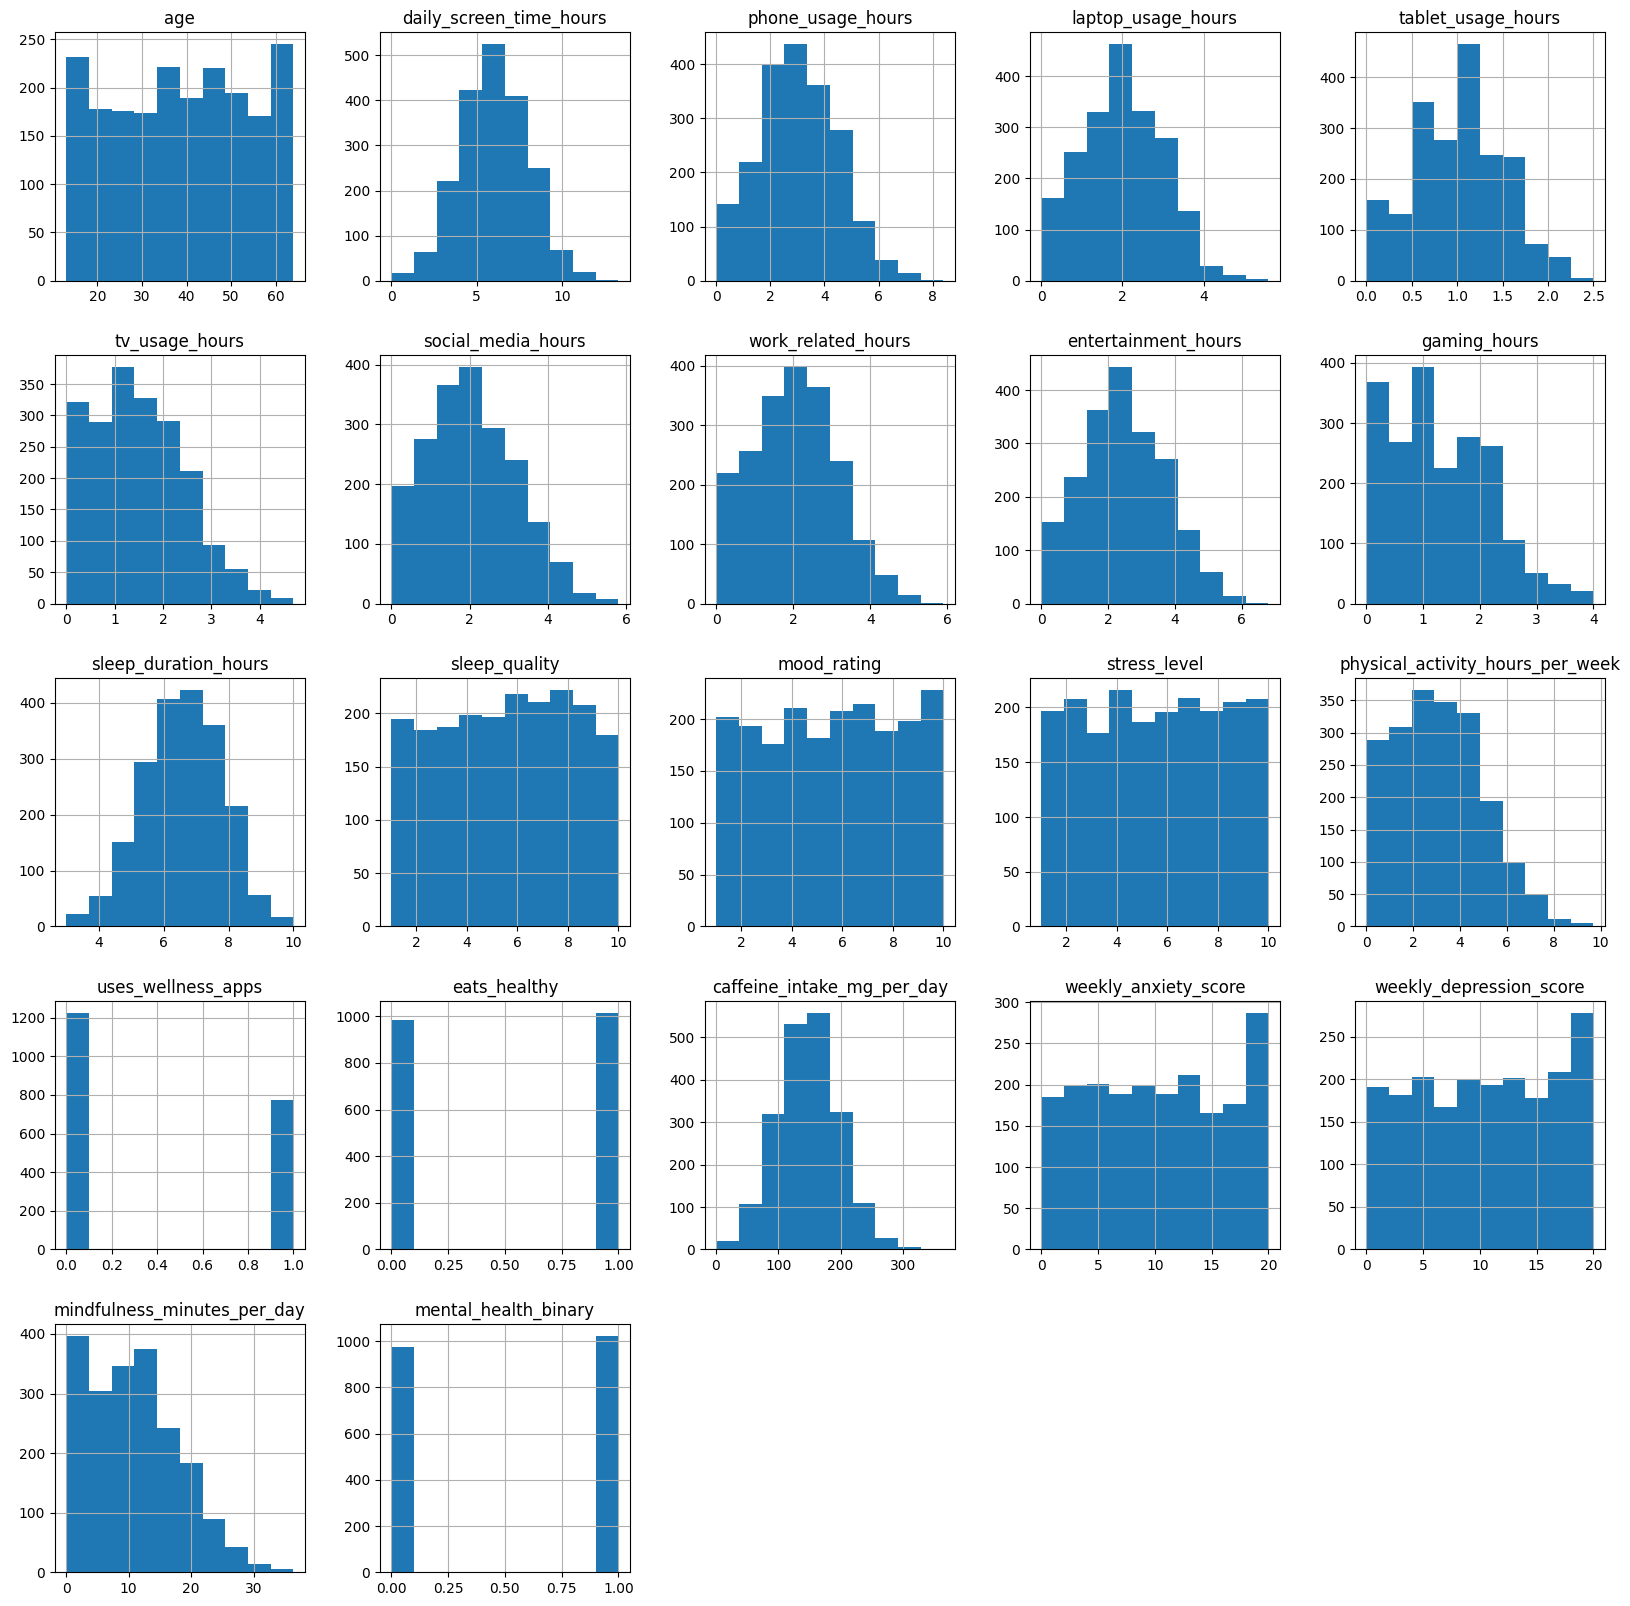

In [ ]:
df.hist(bins=10,figsize=(20,20))
plt.show()

C:\Users\BCSbgayet\AppData\Local\Temp\ipykernel_8620\3957519874.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


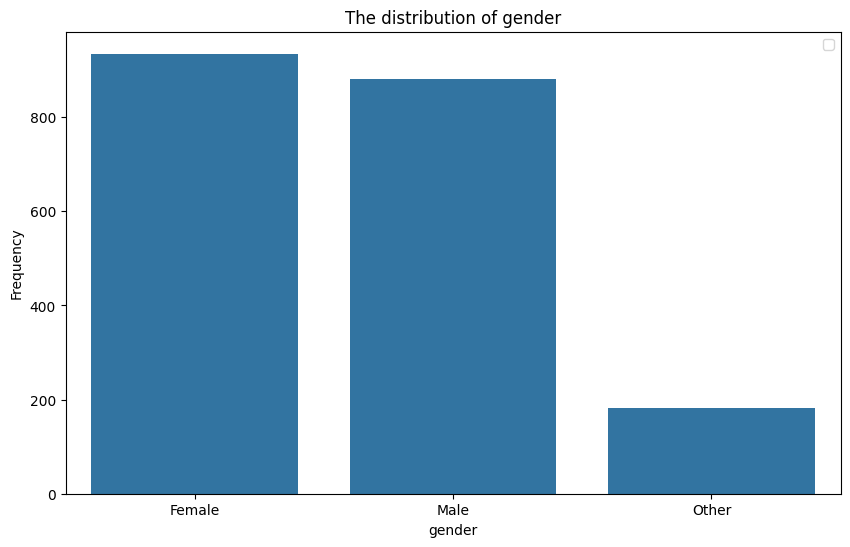

C:\Users\BCSbgayet\AppData\Local\Temp\ipykernel_8620\3957519874.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


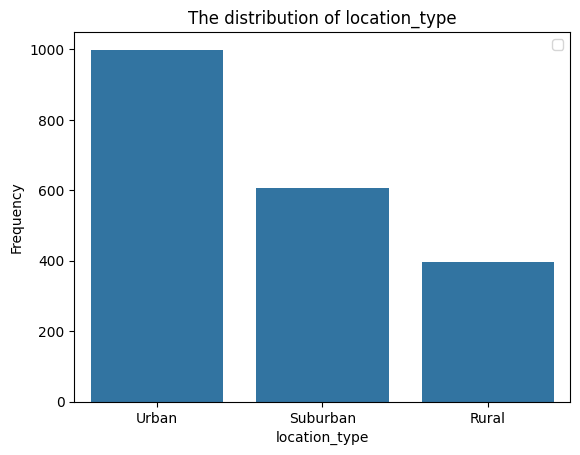

In [ ]:
categorical_col = df.select_dtypes(include='object').columns 

plt.figure(figsize=(10,6))
for col in categorical_col:
    sns.countplot(x=col,data=df)
    plt.ylabel('Frequency')
    plt.title(f'The distribution of {col}')
    plt.legend()
    plt.show()

## Multivariate Analysis

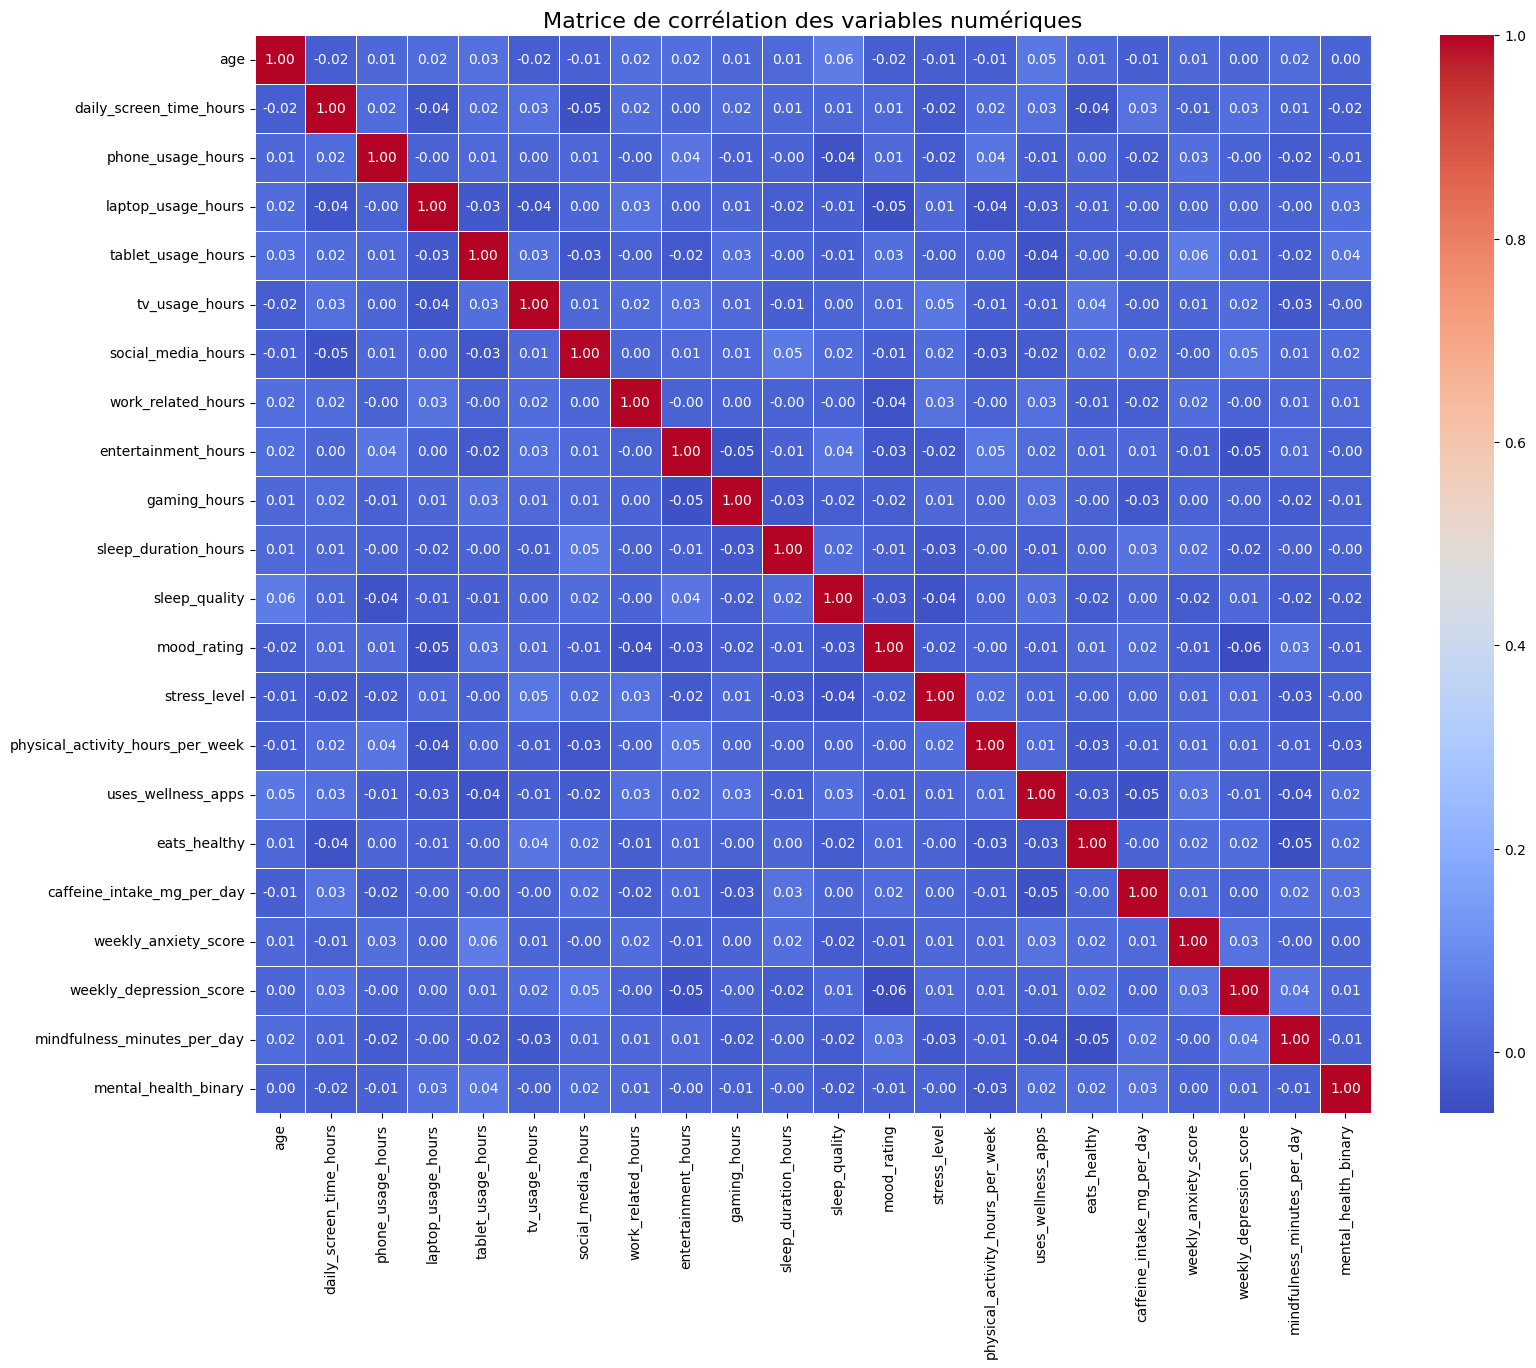

In [7]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(18, 14))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrice de corrélation des variables numériques", fontsize=16)
plt.show()


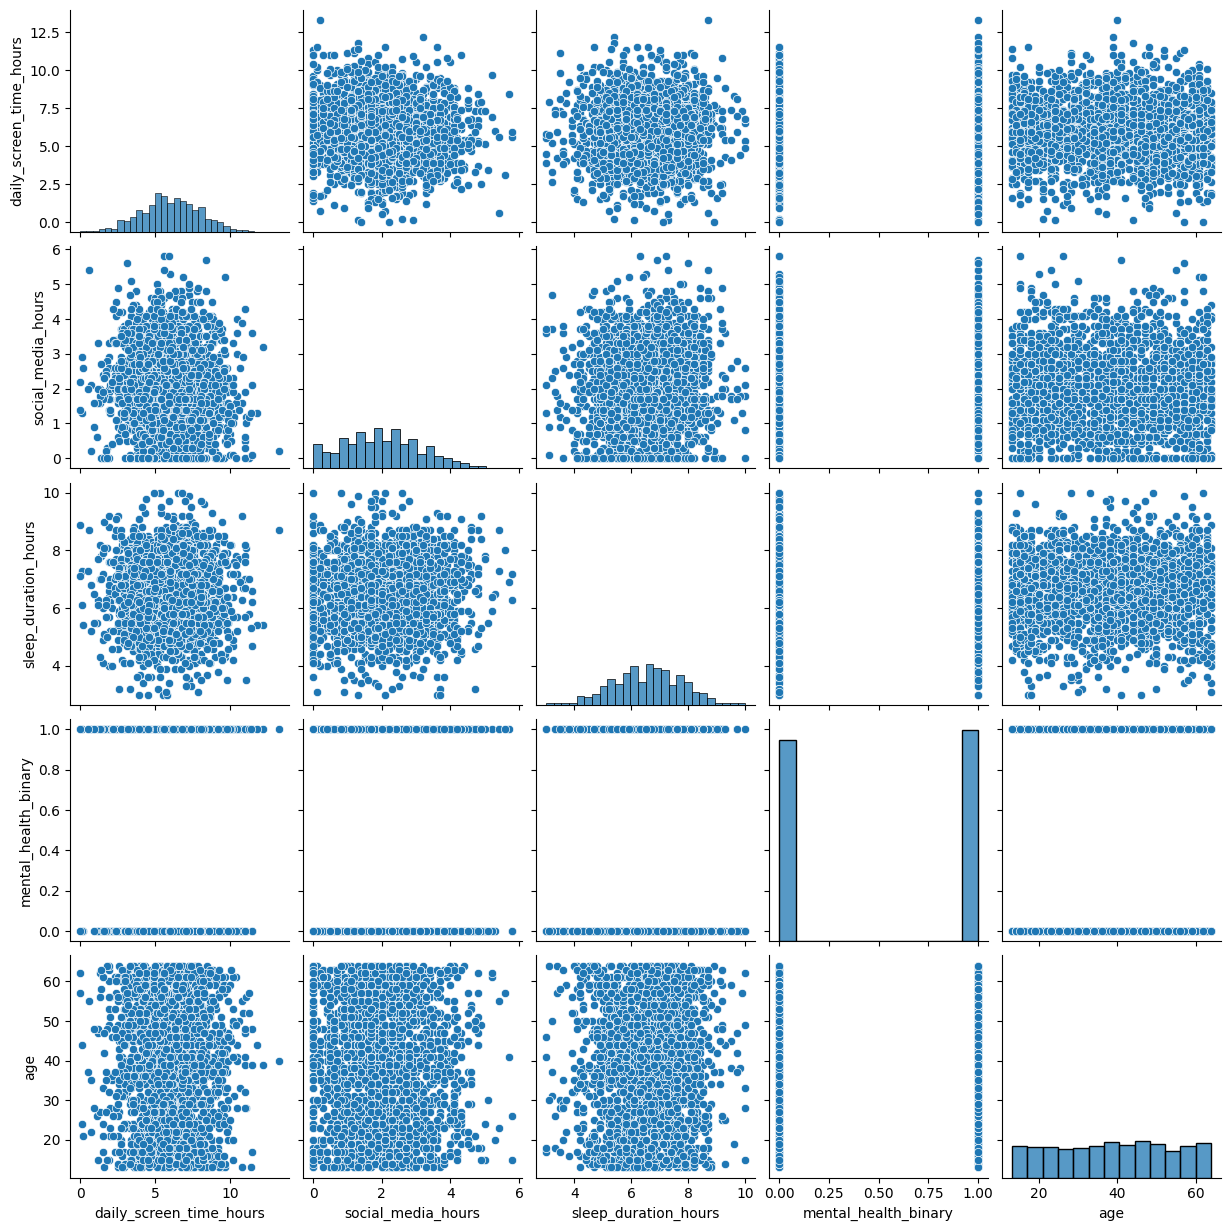

In [ ]:
# Pair plot to examine relationships among selected variables
pairplot_cols = ['daily_screen_time_hours', 'social_media_hours', 'sleep_duration_hours', 'mental_health_binary', 'age']
sns.pairplot(df[pairplot_cols].dropna())
plt.show()

In [35]:
target="mental_health_binary"



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Supprime la target de la liste si elle est dedans
numerical_cols = [col for col in numerical_cols if col != target]

plt.figure(figsize=(15, 5 * len(numerical_cols)))

for i, col in enumerate(numerical_cols):
    plt.subplot(len(numerical_cols), 1, i + 1)
    sns.boxplot(x=target, y=col, data=df)
    plt.title(f'{col} vs {target}')

plt.tight_layout()
plt.show()


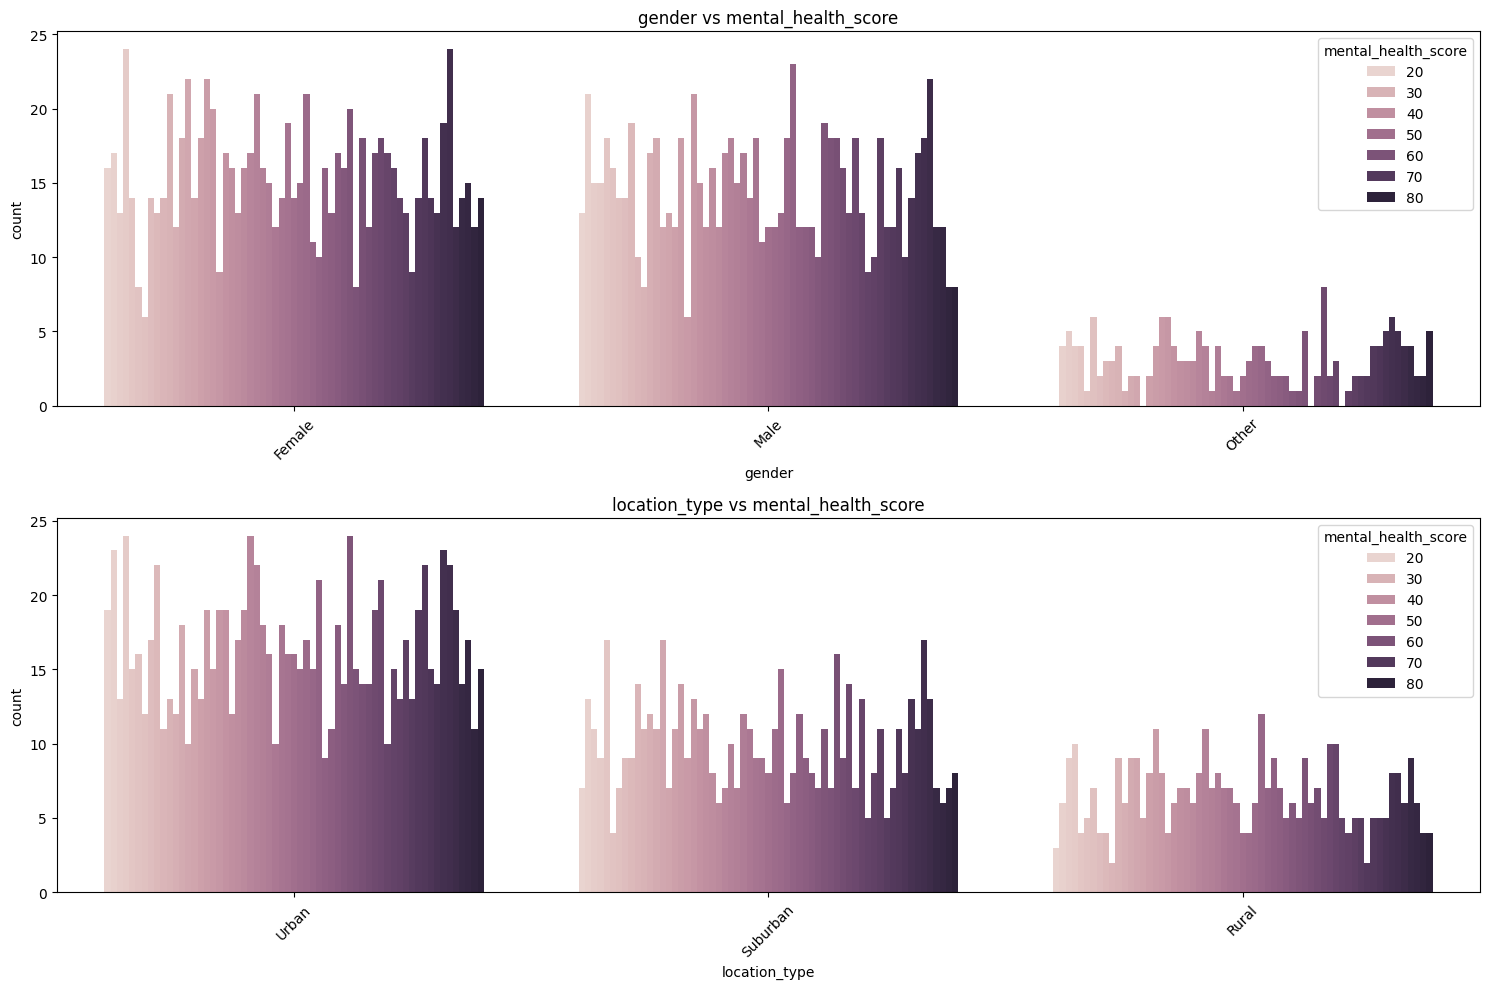

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns

plt.figure(figsize=(15, 5 * len(categorical_cols)))

for i, col in enumerate(categorical_cols):
    plt.subplot(len(categorical_cols), 1, i + 1)
    sns.countplot(data=df, x=col, hue=target)
    plt.title(f'{col} vs {target}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

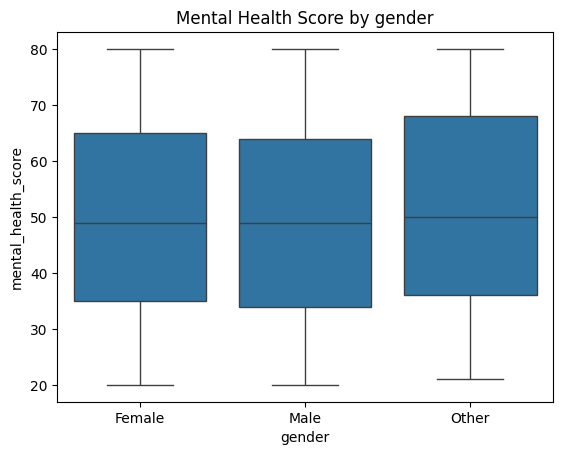

In [ ]:
sns.boxplot(data=df, x='gender', y='mental_health_score')
plt.title('Mental Health Score by gender')
plt.show()

## Feature Engineering

In [9]:
from sklearn.preprocessing import QuantileTransformer, LabelEncoder
label_enc = LabelEncoder()
df['gender'] = label_enc.fit_transform(df['gender'])
df['location_type'] = label_enc.fit_transform(df['location_type'])
x= df.drop(columns='mental_health_binary')
y= df['mental_health_binary']
quantile = QuantileTransformer()
x_transformed = quantile.fit_transform(x)
df_new = pd.DataFrame(x_transformed, columns=x.columns)
df_new['mental_health_binary'] = y.values
df_new.head()


,age,gender,daily_screen_time_hours,phone_usage_hours,laptop_usage_hours,tablet_usage_hours,tv_usage_hours,social_media_hours,work_related_hours,entertainment_hours,...,stress_level,physical_activity_hours_per_week,location_type,uses_wellness_apps,eats_healthy,caffeine_intake_mg_per_day,weekly_anxiety_score,weekly_depression_score,mindfulness_minutes_per_day,mental_health_binary
0,0.745245,0.000000,0.266266,0.610611,0.252252,0.881882,0.553053,0.958959,0.497497,0.124124,...,1.000000,0.117618,1.000000,1.0,1.0,0.320835,0.658659,0.733734,0.213714,0
1,1.000000,0.688188,0.141642,0.636637,0.425926,0.423423,0.702202,0.724725,0.835836,0.124124,...,0.541542,0.739239,0.348849,0.0,1.0,0.521178,0.926426,0.883383,0.315315,1
2,0.539039,1.000000,0.988488,0.272773,0.724224,0.286286,0.759760,0.797297,0.756256,0.902903,...,0.445445,0.518519,0.348849,0.0,0.0,0.799000,0.361361,0.163163,0.332833,0
3,0.268268,1.000000,0.915916,0.000000,0.000000,0.286286,0.841842,0.854354,0.361361,0.183684,...,0.445445,0.000000,0.000000,0.0,1.0,0.062062,0.361361,0.118118,0.244244,0
4,0.815315,0.688188,0.479980,0.190691,0.191692,0.839840,0.553053,0.220721,0.920921,0.092092,...,0.643143,0.495495,1.000000,1.0,1.0,0.924925,0.414414,0.495495,0.000000,1


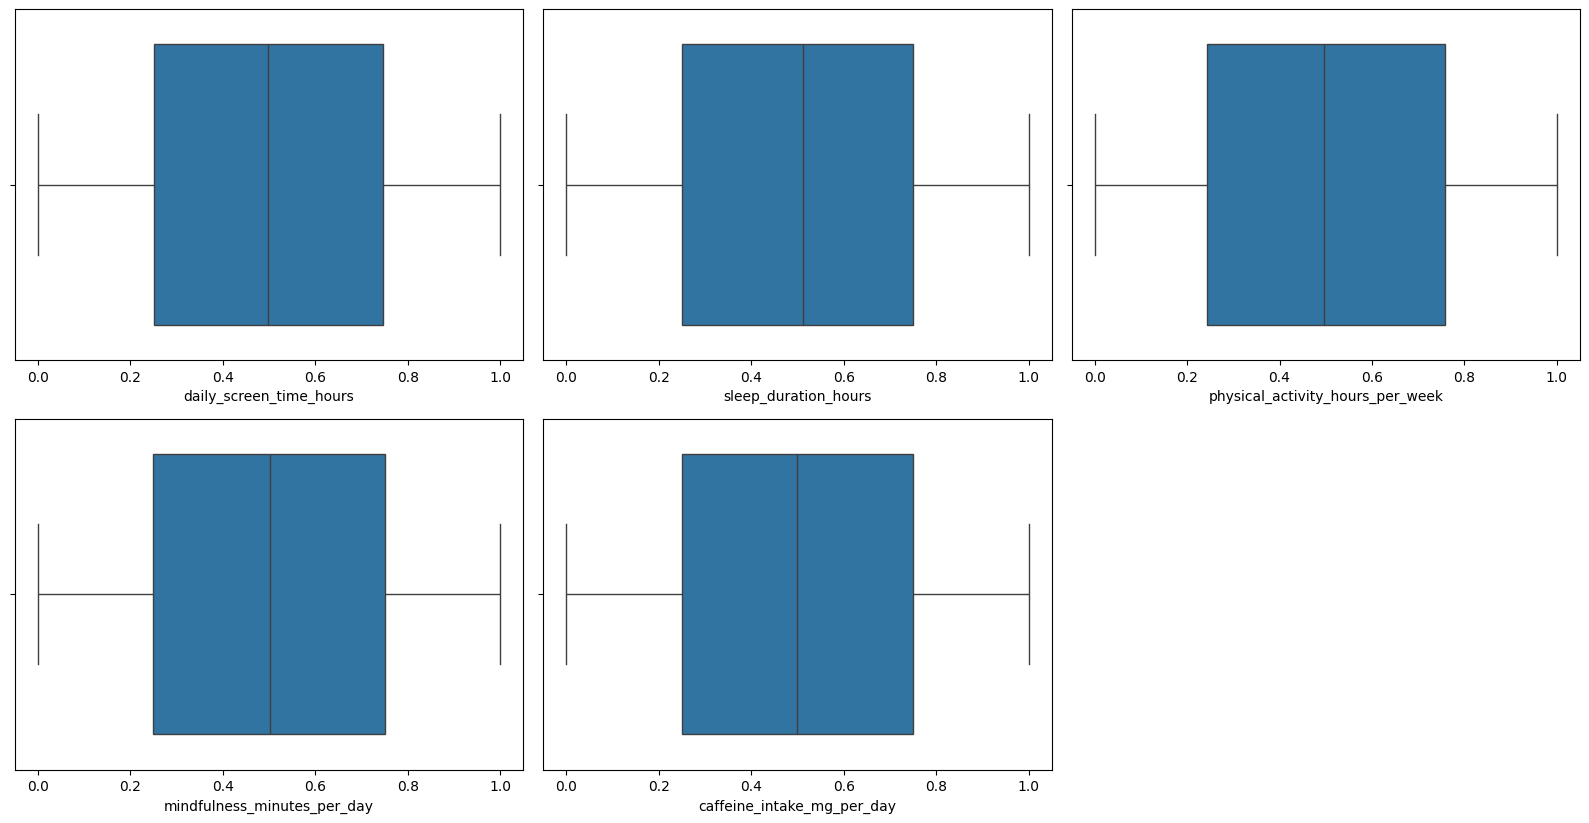

In [10]:
plt.figure(figsize=(16, 12))

plt.subplot(3, 3, 1)
sns.boxplot(x="daily_screen_time_hours", data=df_new)

plt.subplot(3, 3, 2)
sns.boxplot(x="sleep_duration_hours", data=df_new)

plt.subplot(3, 3, 3)
sns.boxplot(x="physical_activity_hours_per_week", data=df_new)

plt.subplot(3, 3, 4)
sns.boxplot(x="mindfulness_minutes_per_day", data=df_new)

plt.subplot(3, 3, 5)
sns.boxplot(x="caffeine_intake_mg_per_day", data=df_new)

plt.tight_layout()
plt.show()

### Modeling

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [12]:
x_train.shape,y_train.shape

((1600, 23), (1600,))

In [13]:
x_test.shape,y_test.shape

((400, 23), (400,))

# **Classification Algorithms**

#### LOGISTIC REGRESSION

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score


log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(x_train, y_train)
y_pred_lr = log_reg.predict(x_test)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Logistic Regression
Accuracy: 0.49
              precision    recall  f1-score   support

           0       0.47      0.40      0.43       195
           1       0.50      0.58      0.54       205

    accuracy                           0.49       400
   macro avg       0.49      0.49      0.48       400
weighted avg       0.49      0.49      0.49       400



### RANDOM FOREST

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_test)

print("Classification Report (Random Forest):\n", classification_report(y_test, rf_pred))
print("\n F1:", f1_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("Accuracy:", accuracy_score(y_test, rf_pred))

Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.51      0.48      0.49       195
           1       0.53      0.57      0.55       205

    accuracy                           0.52       400
   macro avg       0.52      0.52      0.52       400
weighted avg       0.52      0.52      0.52       400


 F1: 0.5484633569739953
Precision: 0.5321100917431193
Recall: 0.5658536585365853
Accuracy: 0.5225


### KNN

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score


knn=KNeighborsClassifier(metric='euclidean', n_neighbors=5)
model=knn.fit(x_train,y_train)

knn_pred = model.predict(x_test)
print("Classification Report is:\n", classification_report(y_test, knn_pred))
print("\n F1:\n",f1_score(y_test,knn_pred))
print("\n Precision score is:\n",precision_score(y_test,knn_pred))
print("\n Recall score is:\n",recall_score(y_test,knn_pred))
print("\n Accuracy score is:\n",accuracy_score(y_test,knn_pred))

Classification Report is:
               precision    recall  f1-score   support

           0       0.51      0.50      0.50       195
           1       0.53      0.54      0.53       205

    accuracy                           0.52       400
   macro avg       0.52      0.52      0.52       400
weighted avg       0.52      0.52      0.52       400


 F1:
 0.5326876513317191

 Precision score is:
 0.5288461538461539

 Recall score is:
 0.5365853658536586

 Accuracy score is:
 0.5175


## SVM

In [36]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(x_train, y_train)
y_pred_svm = svm.predict(x_test)

print(" Support Vector Machine")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))


 Support Vector Machine
Accuracy: 0.5075
              precision    recall  f1-score   support

           0       0.48      0.14      0.22       195
           1       0.51      0.86      0.64       205

    accuracy                           0.51       400
   macro avg       0.50      0.50      0.43       400
weighted avg       0.50      0.51      0.43       400



## Decision Tree

In [32]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)

print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Decision Tree
Accuracy: 0.4375
              precision    recall  f1-score   support

           0       0.42      0.43      0.42       195
           1       0.45      0.45      0.45       205

    accuracy                           0.44       400
   macro avg       0.44      0.44      0.44       400
weighted avg       0.44      0.44      0.44       400



## **TUNING**

### LOGISTIC REGRESSION TUNED

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs']  # 'lbfgs' supporte uniquement l2
}

grid_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_lr, cv=5, scoring='f1')
grid_lr.fit(x_train, y_train)

print(" Best Logistic Regression Params:", grid_lr.best_params_)
print("F1 Score (Best Logistic Regression):", f1_score(y_test, grid_lr.predict(x_test)))


🔍 Best Logistic Regression Params: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
F1 Score (Best Logistic Regression): 0.5244444444444445


### SVM WITH TUNING

In [ ]:
from sklearn.svm import SVC

param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(SVC(), param_grid_svm, cv=5, scoring='f1')
grid_svm.fit(x_train, y_train)

print(" Best SVM Params:", grid_svm.best_params_)
print("F1 Score (Best SVM):", f1_score(y_test, grid_svm.predict(x_test)))


🔍 Best SVM Params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
F1 Score (Best SVM): 0.6776859504132231


### KNN with tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 11, 15],
    'metric': ['euclidean', 'manhattan']
}

grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, scoring='f1')
grid_knn.fit(x_train, y_train)

print(" Best KNN Params:", grid_knn.best_params_)
print("F1 Score (Best KNN):", f1_score(y_test, grid_knn.predict(x_test)))


🔍 Best KNN Params: {'metric': 'manhattan', 'n_neighbors': 3}
F1 Score (Best KNN): 0.47619047619047616


### Random forest Tuned

In [ ]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='f1')
grid_rf.fit(x_train, y_train)

print(" Best RF Params:", grid_rf.best_params_)
print("F1 Score (Best RF):", f1_score(y_test, grid_rf.predict(x_test)))


🔍 Best RF Params: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
F1 Score (Best RF): 0.5110132158590308


## ***Comparing models***

In [50]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd


results = [
    ("Logistic Regression", accuracy_score(y_test, y_pred_lr), f1_score(y_test, y_pred_lr)),
    ("Random Forest", accuracy_score(y_test, rf_pred), f1_score(y_test,rf_pred)),
    ("Decision Tree", accuracy_score(y_test, y_pred_dt), f1_score(y_test, y_pred_dt)),
    ("KNN", accuracy_score(y_test, knn_pred), f1_score(y_test, knn_pred)),
    ("SVM", accuracy_score(y_test, y_pred_svm), f1_score(y_test, y_pred_svm)),
    ("Random Forest tuned", accuracy_score(y_test, grid_rf.best_estimator_.predict(x_test)), f1_score(y_test,grid_rf.best_estimator_.predict(x_test))),
    ("SVM tuned", accuracy_score(y_test, grid_svm.best_estimator_.predict(x_test)), f1_score(y_test, grid_svm.best_estimator_.predict(x_test)))
]

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1-Score"])
results_df = results_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print(" Résumé des performances des modèles :")
print(results_df)

        

 Résumé des performances des modèles :
                 Model  Accuracy  F1-Score
0            SVM tuned    0.5125  0.677686
1                  SVM    0.5075  0.641166
2        Random Forest    0.5225  0.548463
3  Logistic Regression    0.4900  0.536364
4                  KNN    0.5175  0.532688
5  Random Forest tuned    0.4450  0.511013
6        Decision Tree    0.4375  0.449878


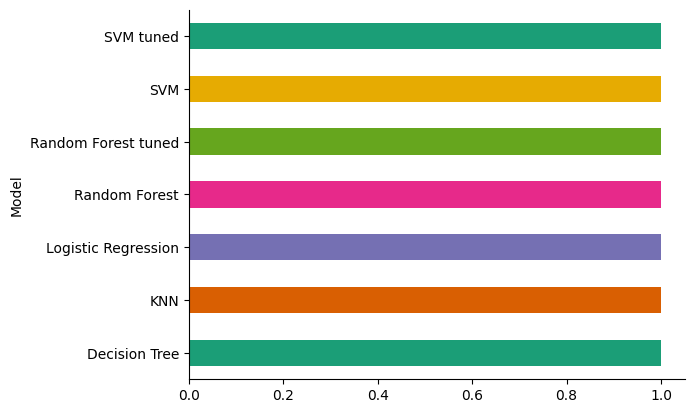

In [46]:
from matplotlib import pyplot as plt
import seaborn as sns
results_df.groupby('Model').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

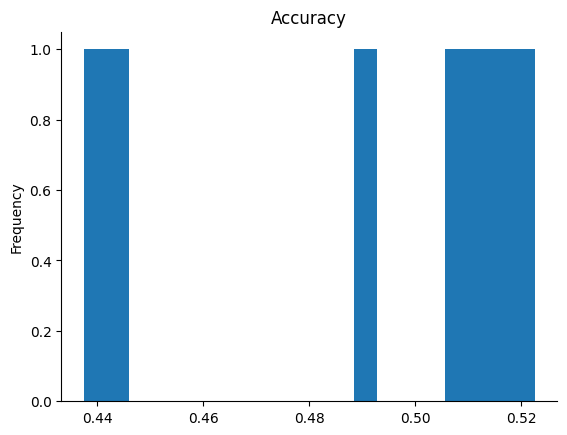

In [47]:
from matplotlib import pyplot as plt
results_df['Accuracy'].plot(kind='hist', bins=20, title='Accuracy')
plt.gca().spines[['top', 'right',]].set_visible(False)

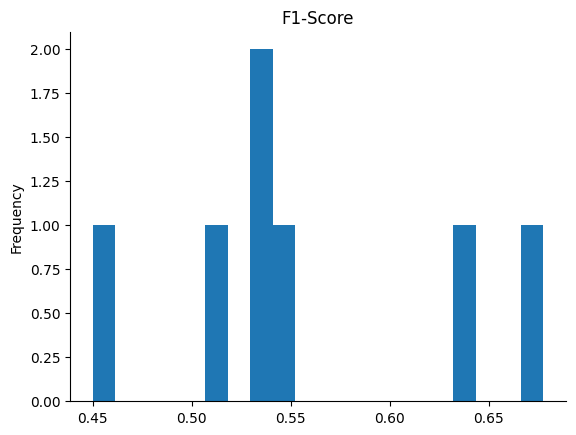

In [49]:
from matplotlib import pyplot as plt
results_df['F1-Score'].plot(kind='hist', bins=20, title='F1-Score')
plt.gca().spines[['top', 'right',]].set_visible(False)